In [95]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

In [96]:
def Get_growthrate_fit(filename, nx):
    x = []
    am = []
    ai = []

    file = open(filename, mode='r')
    lines = file.readlines()

    for line in lines:
        a = line.split()

        x.append(float(a[0]))
        am.append(float(a[1]))
        ai.append(float(a[9]))

    print(nx)

    x = np.array(x)
    am = np.array(am)
    ai = np.array(ai)

    return x, am, ai

In [97]:
def Get_growthrate_START(filename):
    x = []
    ai = []

    file = open(filename, mode='r')
    lines = file.readlines()

    for line in lines:
        a = line.split()

        x.append(float(a[1]))
        ai.append(float(a[8]))

    x = np.array(x)
    ai = np.array(ai)

    return x, ai

In [98]:
filename_START = 'START-w=6, b=8.dat'
x_START, ai_START = Get_growthrate_START(filename_START)
dx = x_START[1:] - x_START[0:-1]
dN_START = -ai_START[1:] * dx
N_START = np.zeros_like(x_START)
for i in range(1, len(x_START)):

    N_START[i] = N_START[i-1] + dN_START[i-1]

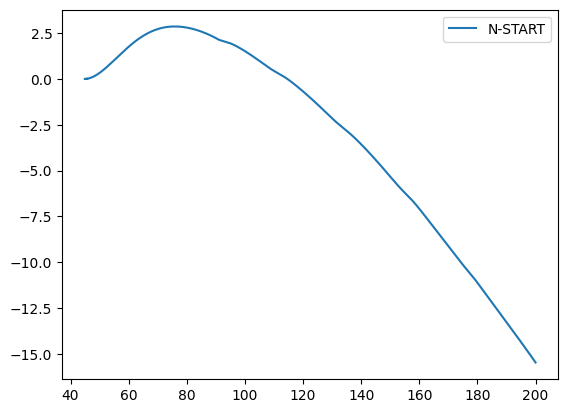

In [99]:
plt.plot(x_START, N_START, label='N-START')
plt.legend(loc=0)

In [100]:
def output():

    f = "N-START-w=6, b=8.plt"

    with open(f, 'w', encoding='utf-8') as file1:

        print('VARIABLES = "X", "ai", "N"', file=file1)
        print('ZONE I = ', len(x_START), ', J = 1, F = POINT', file=file1)

        for i in range(len(x_START)):

            print('%.15f' % x_START[i], '%.15f' % ai_START[i], '%.15f' % N_START[i], file=file1)

output()